# Part 1: Playing with tabular data. The Iris Dataset.

The Iris dataset is a well-known and frequently used dataset in the field of machine learning and statistics. It was introduced by British biologist and statistician Ronald A. Fisher in 1936. The dataset consists of samples from three different species of Iris flowers, namely Setosa, Versicolor, and Virginica. Each species is represented by 50 samples, resulting in a total of 150 data points.

**Features**: The dataset contains four features (attributes) for each sample:

1. Sepal Length (in centimeters)
2. Sepal Width (in centimeters)
3. Petal Length (in centimeters)
4. Petal Width (in centimeters)

**Target Variable**: There is one target variable representing the species of each Iris flower sample. The target variable consists of three classes:
- Setosa (Class 0)
- Versicolor (Class 1)
- Virginica (Class 2)


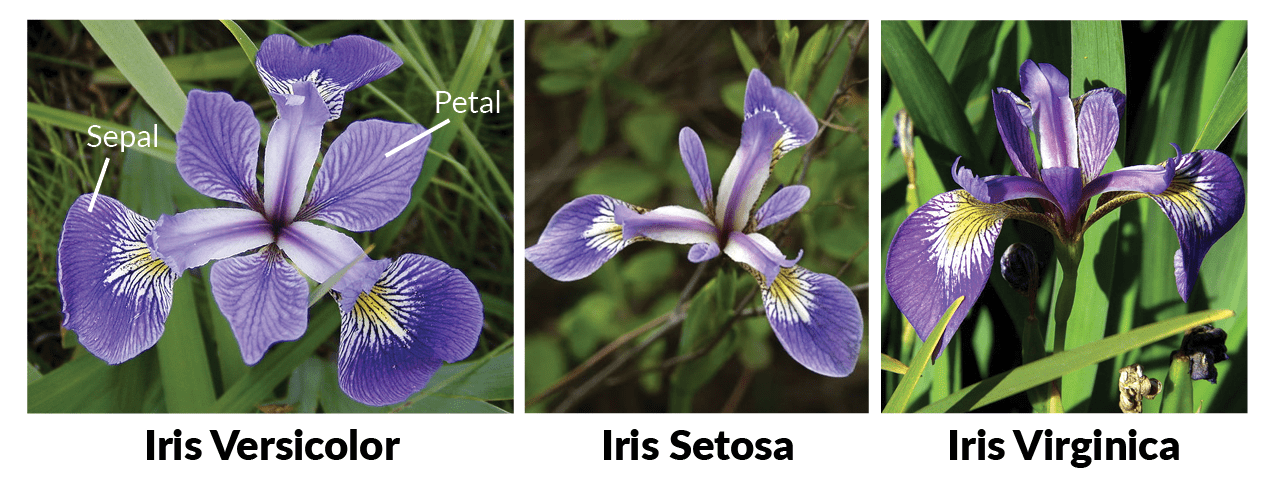

## Exercise 1: Load and understand the data.

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt


Download the dataset in csv format. (https://www.kaggle.com/datasets/arshid/iris-flower-dataset)

Load the dataset into a variable **iris**

In [8]:
import numpy as np
import matplotlib.pyplot as plt

iris = "Iris.csv"
X = np.genfromtxt(iris, delimiter=",", skip_header=1, usecols=(1, 2, 3, 4))
y = np.genfromtxt(iris, delimiter=",", skip_header=1, usecols=(5,), dtype=str)

iris = X

print(X.shape,y.shape)

(150, 4) (150,)


Now create a function that plots two of the columns of the dataset (e.g. sepal length vs petal length) in a [scatter plot](https://matplotlib.org/stable/gallery/shapes_and_collections/scatter.html#sphx-glr-gallery-shapes-and-collections-scatter-py). You can use the instructions:

*   `plt.figure()` to create a new figure
*   `ax.scatter(x_values, y_values)` to plot points (x,y) from two arrays.



In [7]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_features(iris, i, j):
    for especie in np.unique(y):
        mask = (y == especie)
        plt.scatter(iris[mask, i], iris[mask, j], label=especie)
    plt.xlabel(f"característica {i}")
    plt.ylabel(f"característica {j}")
    plt.legend()
    plt.show()

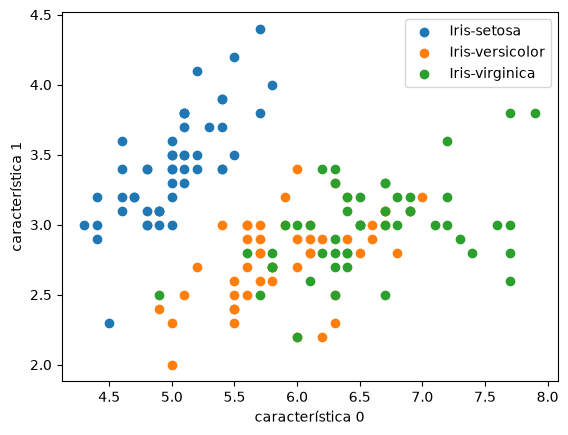

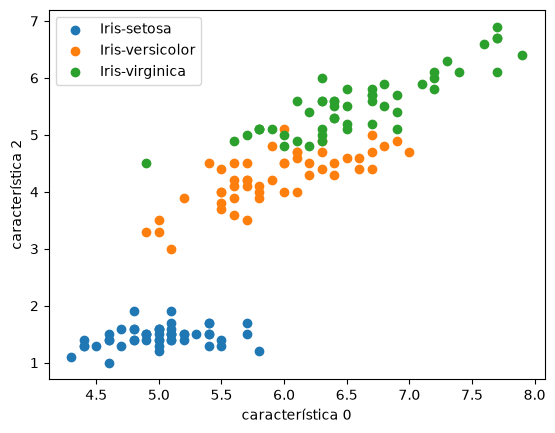

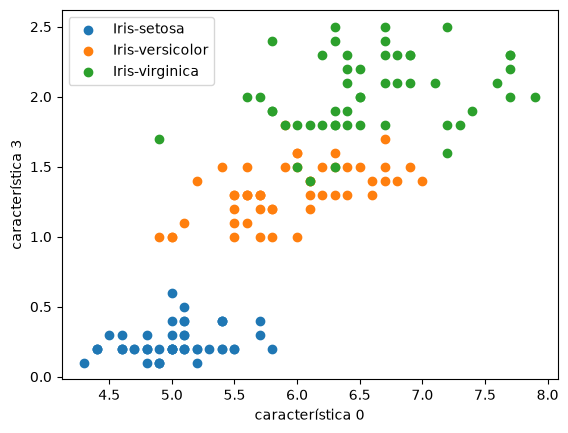

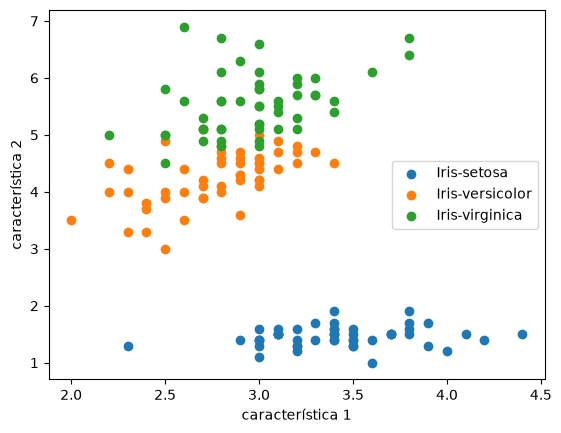

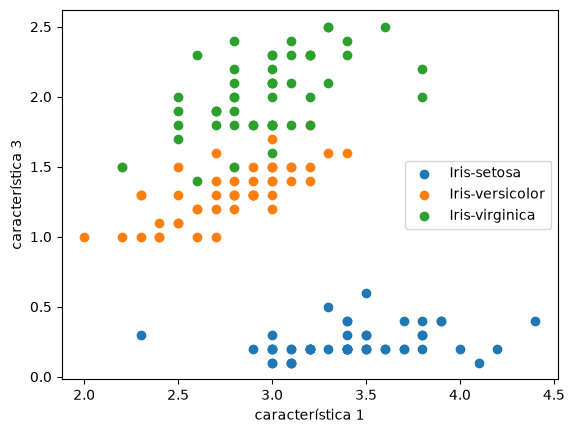

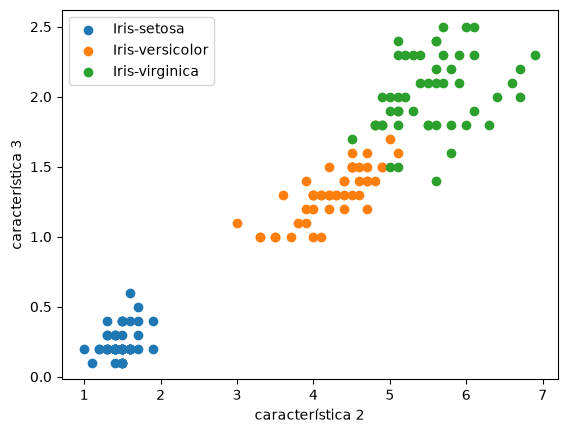

In [10]:
visualize_features(iris,0,1)
visualize_features(iris,0,2)
visualize_features(iris,0,3)
visualize_features(iris,1,2)
visualize_features(iris,1,3)
visualize_features(iris,2,3)

With the function you implemented before, now visualize all the 6 combinations of features.

In [ ]:
# ===============#
# YOUR CODE HERE #
# ===============#





NameError: name 'visualize_features' is not defined

## Excercise 2 - using the dataset

### En el cas de tenir malament l'apartat anterior, carrego el dataset a través de sklearn per estar tots en el mateix punt.

(150, 4) (150,)


Now split the dataset in X (features) and Y (labels).

Then create a function that splits into train/ test based on % amount.

In [ ]:
# ===============#
# YOUR CODE HERE #
# ===============#
from sklearn import datasets
iris_2 = datasets.load_iris()

x = iris.data # CARACTERISTIQUES  LES 4 MESURES DE CADA FLOR
y = iris.target  # TARGETES     L'ESPECIE DE CADA FLOR 

def data_splitter(X,y, train_pct):
    n = len(X)
    barreja = np.random.permutation(n)
    n_train = int(n*train_pct)

    train_idx = barreja[:n_train]
    test_idx = barreja[ n_train:]

    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]
    return  X_train, y_train,X_test, y_test
    



AttributeError: 'numpy.ndarray' object has no attribute 'target'

Use the function that you created previously to split the data so that we can use the 70% of data for training and the 30% for testing.

In [5]:
X_train, y_train, X_test, y_test = data_splitter(X, y, 0.7)
print(X_train.shape, X_test.shape)
print(y_test)

NameError: name 'data_splitter' is not defined

### Logistic Regression
Let's first train a Logistic Regression model (https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression).

In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=200)   # crea el model (encara no sap res)
model.fit(X_train, y_train)                # troba els millors m i n amb les 105 flors
y_pred = model.predict(X_test)             # calcula les probabilitats i tria la classe
print(model.score(X_test, y_test))         # fracció d'encerts

NameError: name 'X_train' is not defined

Check the `ConfusionMatrixDisplay.from_predictions` [function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_predictions) and use it to visualize the confusion matrix for the test set.

[[14  0  0]
 [ 0 14  0]
 [ 0  2 15]]


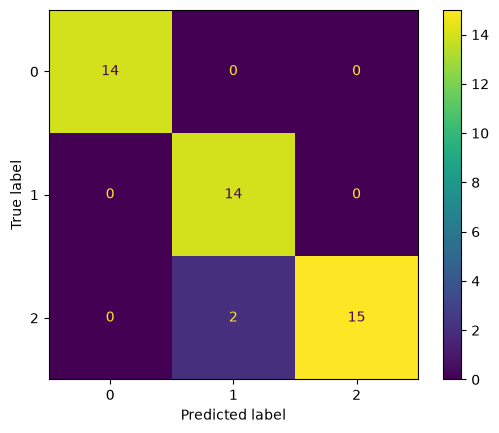

In [28]:
# ===============#
# YOUR CODE HERE #
# ===============#
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

### Decision Tree

Let's now train a DecisionTreeClassifier (https://scikit-learn.org/stable/modules/tree.html#decision-trees). We will train it, predict the test set, visualize the classification tree and its confusion matrix.

In [3]:
# ===============#
# YOUR CODE HERE #
# ===============#
from sklearn.tree import DecisionTreeClassifier

arbre = DecisionTreeClassifier(max_depth=2, random_state=0)
arbre.fit(X_train, y_train)
print(arbre.score(X_test, y_test))

NameError: name 'X_train' is not defined

Check the tree that we just plot... Now check the plots of the beginning. Do you see the relation between them?

### Forests

How to solve Decision Tree problems?


In [2]:
# ===============#
# YOUR CODE HERE #
# ===============#
from sklearn.ensemble import RandomForestClassifier

bosc = RandomForestClassifier(n_estimators=100, random_state=0)
bosc.fit(X_train, y_train)
print(bosc.score(X_train, y_train))
print(bosc.score(X_test, y_test))


NameError: name 'X_train' is not defined

### SVM

Let's now train a SVM classifier (https://scikit-learn.org/stable/modules/svm.html#svm). We will train it, predict the test set and its confusion matrix.

In [34]:
# ===============#
# YOUR CODE HERE #
# ===============#
from sklearn.svm import SVC

svm = SVC()
svm.fit(X_train, y_train)
print(svm.score(X_test, y_test))
print(svm.n_support_)

0.9333333333333333
[ 5 23 20]


### other classifiers

Check other classifiers available in scikit library (at least 2 more)


In [ ]:
# ===============#
# YOUR CODE HERE #
# ===============#



[5.1 1.4]
[1.4 1.3 4.7]
